# Why do large vision-language models hallucinate objects that are not in the image?
### Phase I - How does the model behave? (black-box behavioural analysis of LLaVA)
### Pair (Roland and Fabian): without using generative AI Tools

**Model under study:** LLaVA-1.5-7B (<https://llava-vl.github.io/>)<br>
**Task for Phase 1:**
* The model is a **black box**. We never modify weights, never fine-tune, never train anything, and never read hidden states or attention. We only read **inputs and outputs** (out probabilities in `Yes` / `No` tokens).
* The only "extra" data are ground-truth annotations of the benchmark images (COCO), used to explain behaviour, but they never change the model.

**Data.**
1. **POPE** (Li et al., 2023; `lmms-lab/POPE`) - an established object-hallucination benchmark: 9,000 yes/no questions "*Is there a X in the image?*" on 500 COCO val2014 images, in three negative-sampling regimes (`random`, `popular`, `adversarial`). Exactly half the questions are about objects that *are* present, half about objects that are *absent*, so every "yes" to an absent object is a hallucination.
2. **COCO instance annotations** (train2014 + val2014) - used (a) to describe each POPE image (what is really there, how big, how cluttered) and (b) as a *proxy for training-data statistics*: LLaVA's visual-instruction data are built on COCO train2014 images, so object frequencies and object co-occurrences in COCO train are a natural hypothesis source.
3. **Synthetic control images** (black / white / grey / noise) - designed by us to isolate what the model says when there is *no visual evidence at all*.
4. **Open-ended captions** for a subset of images - to check that the yes/no findings carry over to the free-form setting described in the task ("an object in the background that doesn't exist").

**Hypotheses we created to structure the notebook/ give each plot section a better idea what it is about:**

| # | Hypothesis | Section |
|---|---|---|
| H1 | The model has a *yes-bias*, and hallucination gets worse as negatives get more "plausible" (random < popular < adversarial) | 4 |
| H2 | Hallucinations are *confident*, not borderline guesses; and the model *can* separate present from absent objects - its decision threshold is the problem | 5 |
| H3 | Hallucination is concentrated in a few object classes rather than spread evenly (so the question is what is hallucinated the most)| 6 |
| H4 | Hallucination follows a **co-occurrence prior**: an absent object is claimed when it usually appears together with objects that *are* present | 7 |
| H5 | Scene factors matter: cluttered scenes -> more false "yes"; small objects -> more false "no" | 8 |

## 0. Setup
Running on a GPU (Colab T4 works with `USE_4BIT=True`) + we need to install -q bitsandbytes package

In [1]:
%pip install -q bitsandbytes

In [2]:
import os, re, json, zipfile, math, random, warnings, urllib.request, textwrap, difflib
from collections import Counter, defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from tqdm.auto import tqdm
from PIL import Image
import torch

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110

# ------------------------------- CONFIG -------------------------------
SEED             = 0
MODEL_ID         = "llava-hf/llava-1.5-7b-hf"
N_PER_CATEGORY   = 1000     # POPE questions per category (random/popular/adversarial), balanced yes/no.
                            # Set to None to use all 3,000 per category (9,000 total) - recommended on an L4/A100.
BATCH_SIZE       = 8
USE_4BIT         = True     # True = load weights in 4-bit (fits a free Colab T4; numbers shift slightly)
N_CAPTION_IMAGES = 100      # images used for the open-ended caption analysis
CAPTION_BATCH    = 4
MAX_NEW_TOKENS   = 256
MIN_N            = 8        # min. #questions for an object to be shown in per-object plots
MIN_CELL         = 3        # min. #questions for a cell of a heat-map to be shown
WORKDIR          = "llava_halluc_cache"   # all intermediate results are cached here (safe to re-run)
# ----------------------------------------------------------------------

os.makedirs(WORKDIR, exist_ok=True)
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", DEVICE, "|", torch.cuda.get_device_name(0) if DEVICE == "cuda" else "NO GPU - this will be very slow")

VERDICTS = []   # every hypothesis test appends its verdict here; printed in the final section
CATS = ["random", "popular", "adversarial"]

def wilson(k, n, z=1.96):
    """95% Wilson confidence interval for a proportion k/n."""
    if n == 0:
        return (np.nan, np.nan)
    p = k / n; d = 1 + z * z / n
    c = (p + z * z / (2 * n)) / d
    h = z * np.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / d
    return (c - h, c + h)

device: cuda | Tesla T4


## 1. Load the model (code is basically copied from the github page we use as source)
We load LLaVA-1.5-7B exactly as released, put it in `eval()` mode, switch off gradients, and wrap every call in `torch.inference_mode()`. --> Nothing about the model is changed.

**How we read the model's answer.** LLaVA is an autoregressive LM, so its "answer" to *"Is there a X in the image?"* is the first generated token. Instead of only keeping the decoded word, we read the **next-token probabilities of `Yes` and `No`** from the forward pass.

**Prompt format.** `USER: <image>\n{question}\nAnswer the question using a single word or phrase. ASSISTANT:` (the format LLaVA's authors use for POPE).
**Pre-processing.** The original LLaVA-1.5 pads non-square images to a square with the mean colour before the 336px CLIP encoder; the Hugging Face processor would instead *centre-crop*, silently deleting objects at the border. We replicate the original padding so that "missed" objects are not a pre-processing artefact.

In [3]:
from transformers import AutoProcessor, LlavaForConditionalGeneration

processor = AutoProcessor.from_pretrained(MODEL_ID)
processor.tokenizer.padding_side = "left"          # so that logits[:, -1] is the next token for every row

load_kwargs = dict(torch_dtype=torch.float16, low_cpu_mem_usage=True)
if USE_4BIT:
    from transformers import BitsAndBytesConfig
    load_kwargs["quantization_config"] = BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_compute_dtype=torch.float16)
    load_kwargs["device_map"] = "auto"
    model = LlavaForConditionalGeneration.from_pretrained(MODEL_ID, **load_kwargs)
else:
    model = LlavaForConditionalGeneration.from_pretrained(MODEL_ID, **load_kwargs).to(DEVICE)

model.eval()
for p in model.parameters():
    p.requires_grad_(False)                        # no training, no gradients - ever
print(f"loaded {MODEL_ID}: {sum(p.numel() for p in model.parameters())/1e9:.2f}B parameters")

tok = processor.tokenizer
def _token_ids(words):
    ids = []
    for w in words:
        t = tok(w, add_special_tokens=False).input_ids
        if t:
            ids.append(t[-1])
    return sorted(set(ids))
YES_IDS = _token_ids(["Yes", "yes", "YES"])
NO_IDS  = _token_ids(["No", "no", "NO"])
print("Yes-tokens:", tok.convert_ids_to_tokens(YES_IDS), "| No-tokens:", tok.convert_ids_to_tokens(NO_IDS))

YN_SUFFIX = "\nAnswer the question using a single word or phrase."
def build_prompt(user_text):
    return f"USER: <image>\n{user_text} ASSISTANT:"

def pad_to_square(img, fill=(122, 116, 104)):
    """Original LLaVA-1.5 pre-processing: pad to a square with the CLIP mean colour (instead of centre-cropping)."""
    w, h = img.size
    if w == h:
        return img
    s = max(w, h)
    canvas = Image.new("RGB", (s, s), fill)
    canvas.paste(img, ((s - w) // 2, (s - h) // 2))
    return canvas

@torch.inference_mode()
def yes_no_scores(images, questions):
    """One forward pass per batch. Returns log P(Yes), log P(No) (summed over casing variants) and the arg-max token."""
    images = [pad_to_square(im.convert("RGB")) for im in images]
    prompts = [build_prompt(q + YN_SUFFIX) for q in questions]
    inputs = processor(images=images, text=prompts, return_tensors="pt", padding=True).to(model.device, torch.float16)
    logits = model(**inputs).logits[:, -1, :].float()
    logp = torch.log_softmax(logits, dim=-1)
    ly = torch.logsumexp(logp[:, YES_IDS], dim=-1)
    ln = torch.logsumexp(logp[:, NO_IDS], dim=-1)
    top = tok.convert_ids_to_tokens(logp.argmax(-1).tolist())
    return ly.cpu().numpy(), ln.cpu().numpy(), top

@torch.inference_mode()
def generate_text(images, instruction, max_new_tokens=256):
    """Greedy decoding (no sampling) for the open-ended caption analysis."""
    images = [pad_to_square(im.convert("RGB")) for im in images]
    prompts = [build_prompt(instruction)] * len(images)
    inputs = processor(images=images, text=prompts, return_tensors="pt", padding=True).to(model.device, torch.float16)
    out = model.generate(**inputs, max_new_tokens=max_new_tokens, do_sample=False)
    new = out[:, inputs["input_ids"].shape[1]:]
    return [t.strip() for t in tok.batch_decode(new, skip_special_tokens=True)]

# quick smoke test
_im = Image.new("RGB", (336, 336), (128, 128, 128))
print(yes_no_scores([_im], ["Is there a dog in the image?"]))

model.safetensors.index.json:   0%|          | 0.00/70.1k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 3 files:   0%|          | 0/3 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/686 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/141 [00:00<?, ?B/s]

loaded llava-hf/llava-1.5-7b-hf: 3.66B parameters
Yes-tokens: ['▁Yes', '▁yes', '▁YES'] | No-tokens: ['▁no', '▁No', '▁NO']
(array([-4.033546], dtype=float32), array([-0.01791624], dtype=float32), ['▁No'])


## 2. Data: POPE benchmark + COCO annotations (code from git source)
POPE rows: `question` ("Is there a X in the image?"), `answer` (yes/no), `image_source` (COCO val2014 file), `category` (`random` / `popular` / `adversarial`).
* **random**: absent objects sampled at random.
* **popular**: absent objects chosen among the most frequent COCO classes.
* **adversarial**: absent objects chosen among those that most often co-occurd with the objects that are present.

We then attach COCO annotations to every question so that we can later ask why an answer was wrong.

In [4]:
from datasets import load_dataset

pope = load_dataset("lmms-lab/POPE", split="test")                 # images are decoded lazily
meta = pope.remove_columns("image").to_pandas()                    # metadata only (no image decoding)
meta["row"]       = np.arange(len(meta))
meta["object"]    = meta.question.str.extract(r"Is there (?:a|an) (.+) in the image\?")[0].str.strip()
meta["label_yes"] = (meta.answer.str.lower() == "yes").astype(int)
meta["coco_id"]   = meta.image_source.str.extract(r"(\d+)$")[0].astype(int)

print(f"{len(meta)} questions | {meta.coco_id.nunique()} images | {meta.object.nunique()} distinct object strings")
print("unparsed questions:", meta.object.isna().sum())
display(meta.groupby(["category", "answer"]).size().unstack())
display(meta.drop(columns=["image_source"]).head())

README.md:   0%|          | 0.00/2.16k [00:00<?, ?B/s]

data/test-00000-of-00003.parquet: reconstructing file:   0%|          |  0.00B / 85.0MB            

data/test-00000-of-00003.parquet: downloading bytes:           |  0.00B            

data/test-00001-of-00003.parquet: reconstructing file:   0%|          |  0.00B / 85.0MB            

data/test-00001-of-00003.parquet: downloading bytes:           |  0.00B            

data/test-00002-of-00003.parquet: reconstructing file:   0%|          |  0.00B / 85.0MB            

data/test-00002-of-00003.parquet: downloading bytes:           |  0.00B            

Generating test split:   0%|          | 0/9000 [00:00<?, ? examples/s]

9000 questions | 500 images | 79 distinct object strings
unparsed questions: 57


answer,no,yes
category,,
adversarial,1500,1500
popular,1500,1500
random,1500,1500


,id,question_id,question,answer,category,row,object,label_yes,coco_id
0,0,1,Is there a snowboard in the image?,yes,adversarial,0,snowboard,1,310196
1,1,2,Is there a backpack in the image?,no,adversarial,1,backpack,0,310196
2,2,3,Is there a person in the image?,yes,adversarial,2,person,1,310196
3,3,4,Is there a car in the image?,no,adversarial,3,car,0,310196
4,4,5,Is there a skis in the image?,yes,adversarial,4,skis,1,310196


In [5]:
# ---- COCO annotations (one ~240 MB download, cached) -------------------------------------------------
ANN_URL = "http://images.cocodataset.org/annotations/annotations_trainval2014.zip"
ANN_ZIP = f"{WORKDIR}/annotations_trainval2014.zip"
if not os.path.exists(ANN_ZIP):
    print("downloading COCO annotations ...")
    urllib.request.urlretrieve(ANN_URL, ANN_ZIP)

def load_instances(split):
    """-> category names, image sizes, and per-image {category: (n_instances, total_area)}"""
    with zipfile.ZipFile(ANN_ZIP) as z, z.open(f"annotations/instances_{split}2014.json") as f:
        d = json.load(f)
    cats = {c["id"]: c["name"] for c in d["categories"]}
    sizes = {im["id"]: (im["width"], im["height"]) for im in d["images"]}
    per = defaultdict(dict)
    for a in d["annotations"]:
        n, ar = per[a["image_id"]].get(cats[a["category_id"]], (0, 0.0))
        per[a["image_id"]][cats[a["category_id"]]] = (n + 1, ar + a["area"])
    del d
    return cats, sizes, dict(per)

cats_val, imgs_val, ann_val = load_instances("val")      # ground truth for the POPE images
cats_tr,  imgs_tr,  ann_tr  = load_instances("train")    # proxy for the statistics of LLaVA's (COCO-based) training data
COCO_CATS = sorted(cats_tr.values())

# ---- "Training-data" statistics: how often does each object appear, and which objects appear together? ----
n_img_train = len(imgs_tr)
cat_img_count, pair_count = Counter(), Counter()
for iid, cd in ann_tr.items():
    cs = sorted(cd)
    cat_img_count.update(cs)
    for a in cs:
        for b in cs:
            if a != b:
                pair_count[(a, b)] += 1
FREQ = pd.Series({c: cat_img_count[c] / n_img_train for c in COCO_CATS})            # P(object appears in an image)
COND_MAT = pd.DataFrame(0.0, index=COCO_CATS, columns=COCO_CATS)                      # P(row-object | column-object present)
for (a, b), n in pair_count.items():
    COND_MAT.at[a, b] = n / cat_img_count[b]
print(f"COCO-train: {n_img_train} images | most frequent objects:", ", ".join(FREQ.sort_values(ascending=False).head(6).index))
del ann_tr

downloading COCO annotations ...
COCO-train: 82783 images | most frequent objects: person, chair, car, dining table, cup, bottle


In [6]:
# ---- normalise POPE object strings to COCO names ----
ALIAS = {"dinning table": "dining table", "hair dryer": "hair drier", "tennis racquet": "tennis racket",
         "sofa": "couch", "television": "tv", "motorbike": "motorcycle", "cellphone": "cell phone"}
COCO_SET = set(COCO_CATS)
def norm_obj(o):
    o = ALIAS.get(o.lower().strip(), o.lower().strip())
    if o in COCO_SET:
        return o
    m = difflib.get_close_matches(o, COCO_CATS, n=1, cutoff=0.8)
    return m[0] if m else None
obj_map = {o: norm_obj(o) for o in meta.object.dropna().unique()}
print("non-identity mappings:", {k: v for k, v in obj_map.items() if k != v})
print("unmatched objects (dropped from COCO-based analyses):", [k for k, v in obj_map.items() if v is None])
meta["obj"] = meta.object.map(obj_map)

# ---- per-question descriptors from COCO ground truth ----
feat = []
for coco_id, obj in zip(meta.coco_id, meta.obj):
    cd = ann_val.get(coco_id, {})
    w, h = imgs_val[coco_id]
    present = set(cd)
    ctx = [c for c in present if c != obj]
    n_obj, area = cd.get(obj, (0, 0.0))
    ok = isinstance(obj, str) and obj in COND_MAT.index
    cooc = [COND_MAT.at[obj, c] for c in ctx] if ok else []
    lifts = [COND_MAT.at[obj, c] / FREQ[obj] for c in ctx] if ok and FREQ[obj] > 0 else []
    feat.append(dict(
        gt_present    = int(obj in present),
        img_n_inst    = sum(v[0] for v in cd.values()),              # clutter: number of annotated instances
        img_n_cat     = len(present),                                # number of distinct annotated categories
        obj_n_inst    = n_obj,
        obj_area_frac = area / (w * h) if n_obj else np.nan,         # how large is the queried object (if present)
        cooc_max      = max(cooc) if cooc else 0.0,                  # max_c P(obj | c present)  (what 'adversarial' selects on)
        lift_max      = max(lifts) if lifts else 0.0,                # max_c P(obj | c) / P(obj)  (association beyond base rate)
        ctx_list      = ",".join(sorted(ctx)),
    ))
meta = pd.concat([meta, pd.DataFrame(feat, index=meta.index)], axis=1)
meta["freq_prior"] = meta.obj.map(FREQ)
meta["log_freq"]   = np.log10(meta.freq_prior)

# sanity check of the join: POPE 'yes' objects must be annotated in COCO, POPE 'no' objects must not be
print("\nP(object annotated in COCO val | POPE says present / absent):")
print(meta.groupby("label_yes").gt_present.mean().rename({0: "POPE absent", 1: "POPE present"}).round(4).to_string())

non-identity mappings: {}
unmatched objects (dropped from COCO-based analyses): []

P(object annotated in COCO val | POPE says present / absent):
label_yes
POPE absent     0.0000
POPE present    0.8944


## 3. Run the model on POPE (code mostly from our git source)
We draw a **stratified sample** (equal numbers of present/absent questions in each of the three categories) and score every question with one forward pass. Results are cached to disk, so re-running the notebook never repeats work. With `N_PER_CATEGORY=1000` this is 3,000 questions; set it to `None` for the full 9,000.

For every question we keep `log P(Yes)` and `log P(No)` and derive
* `margin = log P(Yes) - log P(No)` (the model's evidence for "yes"; > 0 means the model answers "yes"),
* `p_yes = sigmoid(margin)`, `pred_yes = margin > 0`,
* `mass = P(Yes) + P(No)` - sanity check that the model really answers with one of the two words,
* `outcome` in {TP, FP, TN, FN}. **FP = hallucination** (model says an absent object is present).

In [7]:
if N_PER_CATEGORY is None:
    sample = meta.copy()
else:
    n_each = min(N_PER_CATEGORY // 2, meta.groupby(["category", "label_yes"]).size().min())
    sample = (meta.groupby(["category", "label_yes"], group_keys=False)
                  .sample(n=n_each, random_state=SEED))
sample = sample.sort_values("row").reset_index(drop=True)
print(f"{len(sample)} questions selected ({sample.coco_id.nunique()} distinct images)")

RES_PATH = f"{WORKDIR}/pope_scores_{MODEL_ID.split('/')[-1]}{'_4bit' if USE_4BIT else ''}.csv"
done = pd.read_csv(RES_PATH) if os.path.exists(RES_PATH) else pd.DataFrame(columns=["row", "logp_yes", "logp_no", "top_token"])
todo = sample[~sample.row.isin(done.row)]
print(f"cached: {len(done)} | to run: {len(todo)}")

new_rows = []
for bi, i in enumerate(tqdm(range(0, len(todo), BATCH_SIZE), desc="LLaVA on POPE")):
    chunk = todo.iloc[i:i + BATCH_SIZE]
    imgs = [pope[int(r)]["image"] for r in chunk.row]
    ly, ln, top = yes_no_scores(imgs, chunk.question.tolist())
    new_rows += [dict(row=int(r), logp_yes=float(a), logp_no=float(b), top_token=t)
                 for r, a, b, t in zip(chunk.row, ly, ln, top)]
    if (bi + 1) % 25 == 0:
        pd.concat([done, pd.DataFrame(new_rows)]).to_csv(RES_PATH, index=False)
done = pd.concat([done, pd.DataFrame(new_rows)]).drop_duplicates("row")
done = done.astype({"row": int, "logp_yes": float, "logp_no": float, "top_token": str})
done.to_csv(RES_PATH, index=False)

R = sample.merge(done, on="row")
R["margin"]   = R.logp_yes - R.logp_no
R["p_yes"]    = 1 / (1 + np.exp(-R.margin))
R["pred_yes"] = (R.margin > 0).astype(int)
R["correct"]  = (R.pred_yes == R.label_yes)
R["conf"]     = np.maximum(R.p_yes, 1 - R.p_yes)                    # confidence in whichever answer was given
R["mass"]     = np.exp(R.logp_yes) + np.exp(R.logp_no)
R["outcome"]  = np.select([(R.label_yes == 1) & (R.pred_yes == 1), (R.label_yes == 0) & (R.pred_yes == 1),
                           (R.label_yes == 0) & (R.pred_yes == 0)], ["TP", "FP", "TN"], default="FN")

print(f"\nsanity: median P(Yes)+P(No) = {R['mass'].median():.3f} | arg-max token is Yes/No in "
      f"{R.top_token.str.lower().str.strip('▁').isin(['yes','no']).mean()*100:.1f}% of questions")
print(R.outcome.value_counts().to_string())

3000 questions selected (500 distinct images)
cached: 0 | to run: 3000


LLaVA on POPE:   0%|          | 0/375 [00:00<?, ?it/s]


sanity: median P(Yes)+P(No) = 1.000 | arg-max token is Yes/No in 100.0% of questions
outcome
TN    1427
TP    1159
FN     341
FP      73


## 4. First Peek: yes-bias + three negative-sampling regimes (H1)
Aggregate accuracy hides which way the model errs. Here we separate the two error types:
* **FPR** (false-positive rate) = P(model says "yes" | object absent) -> this is the hallucination rate.
* **FNR** (false-negative rate) = P(model says "no" | object present) -> the model misses a real object.

If the model errs mostly through FPR, and FPR grows from `random` -> `popular` -> `adversarial`, hallucination is driven by how plausible the absent object is, not by random perception noise.

,n,accuracy,precision,recall,yes_ratio,FPR,FNR,TP,FP,TN,FN
category,,,,,,,,,,,
random,1000,0.878,0.972,0.778,0.400,0.022,0.222,389,11,489,111
popular,1000,0.873,0.963,0.776,0.403,0.030,0.224,388,15,485,112
adversarial,1000,0.835,0.890,0.764,0.429,0.094,0.236,382,47,453,118
ALL,3000,0.862,0.941,0.773,0.411,0.049,0.227,1159,73,1427,341


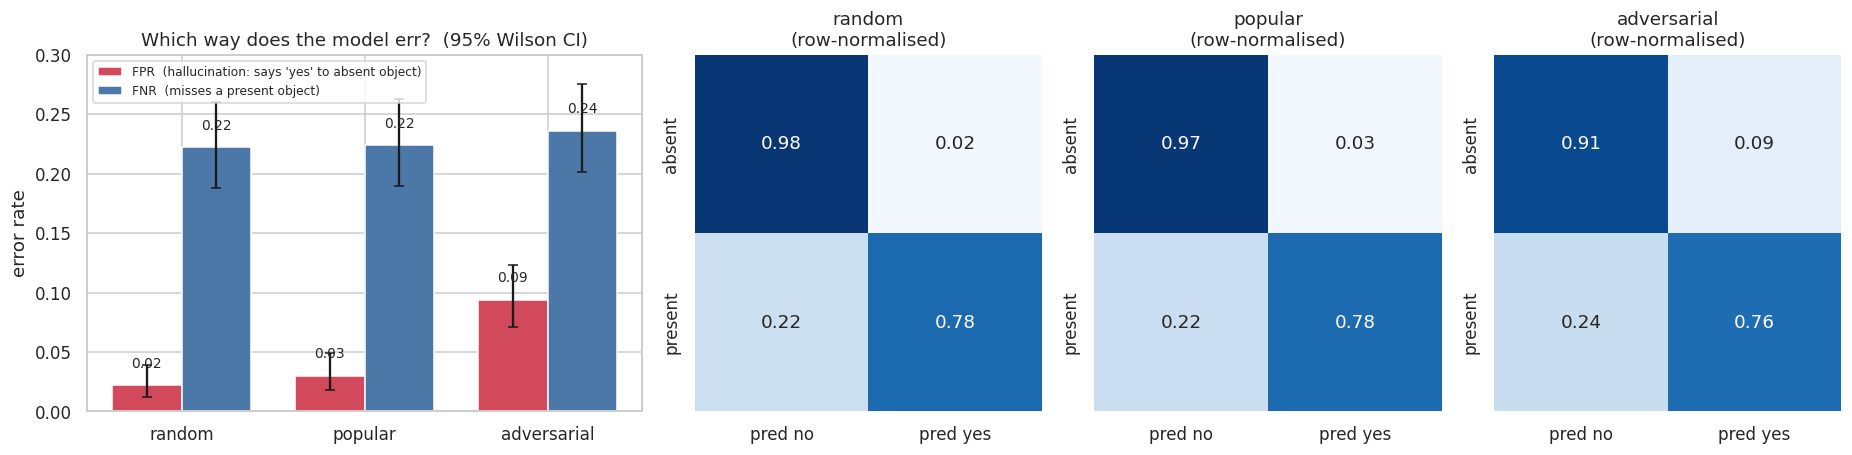

yes-ratio = 0.411 vs. 0.500 true share of 'present' (binomial test p = 1.2e-22)
FPR random/popular/adversarial = [0.022 0.03  0.094] (random vs. adversarial: chi2 p = 2.2e-06)
FPR / FNR ratio overall = 0.2x -> errors are not dominated by one error type


In [8]:
rows = []
for c in CATS + ["ALL"]:
    d = R if c == "ALL" else R[R.category == c]
    pos, neg = d[d.label_yes == 1], d[d.label_yes == 0]
    tp, fn = int(pos.pred_yes.sum()), int((1 - pos.pred_yes).sum())
    fp, tn = int(neg.pred_yes.sum()), int((1 - neg.pred_yes).sum())
    rows.append(dict(category=c, n=len(d), accuracy=d.correct.mean(), precision=tp / max(tp + fp, 1),
                     recall=tp / max(tp + fn, 1), yes_ratio=d.pred_yes.mean(),
                     FPR=fp / max(fp + tn, 1), FNR=fn / max(tp + fn, 1), TP=tp, FP=fp, TN=tn, FN=fn))
summary = pd.DataFrame(rows).set_index("category")
display(summary.round(3))

fig = plt.figure(figsize=(17, 4.3))
gs = fig.add_gridspec(1, 4, width_ratios=[1.6, 1, 1, 1])
ax = fig.add_subplot(gs[0])
x = np.arange(len(CATS)); w = 0.38
for j, (name, num, den, col) in enumerate([("FPR  (hallucination: says 'yes' to absent object)", "FP", ("FP", "TN"), "#d1495b"),
                                          ("FNR  (misses a present object)", "FN", ("FN", "TP"), "#4c78a8")]):
    p = np.array([summary.loc[c, num] / (summary.loc[c, den[0]] + summary.loc[c, den[1]]) for c in CATS])
    ci = np.array([wilson(summary.loc[c, num], summary.loc[c, den[0]] + summary.loc[c, den[1]]) for c in CATS])
    ax.bar(x + (j - .5) * w, p, w, yerr=[p - ci[:, 0], ci[:, 1] - p], capsize=3, color=col, label=name)
    for xi, pi in zip(x + (j - .5) * w, p):
        ax.text(xi, pi + 0.015, f"{pi:.2f}", ha="center", fontsize=9)
ax.set_xticks(x); ax.set_xticklabels(CATS); ax.set_ylabel("error rate"); ax.set_ylim(0, max(0.3, summary[["FPR", "FNR"]].values.max() * 1.25))
ax.set_title("Which way does the model err?  (95% Wilson CI)"); ax.legend(fontsize=8, loc="upper left")
for k, c in enumerate(CATS):
    a = fig.add_subplot(gs[k + 1])
    s = summary.loc[c]
    cm = np.array([[s.TN, s.FP], [s.FN, s.TP]], float); cm = cm / cm.sum(1, keepdims=True)
    sns.heatmap(cm, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, cbar=False, ax=a,
                xticklabels=["pred no", "pred yes"], yticklabels=["absent", "present"])
    a.set_title(f"{c}\n(row-normalised)")
plt.tight_layout(); plt.show()

# ---- tests ----
bt = stats.binomtest(int(R.pred_yes.sum()), len(R), R.label_yes.mean())
neg = R[R.label_yes == 0]
ct = pd.crosstab(neg.category, neg.pred_yes).reindex(CATS)
chi_ra = stats.chi2_contingency(ct.loc[["random", "adversarial"]])[1]
fpr = summary.loc[CATS, "FPR"]
print(f"yes-ratio = {summary.loc['ALL','yes_ratio']:.3f} vs. {R.label_yes.mean():.3f} true share of 'present' (binomial test p = {bt.pvalue:.2g})")
print(f"FPR random/popular/adversarial = {fpr.values.round(3)} (random vs. adversarial: chi2 p = {chi_ra:.2g})")
print(f"FPR / FNR ratio overall = {summary.loc['ALL','FPR'] / max(summary.loc['ALL','FNR'], 1e-9):.1f}x -> errors are "
      f"{'dominated by hallucinations (false yes)' if summary.loc['ALL','FPR'] > 1.5 * summary.loc['ALL','FNR'] else 'not dominated by one error type'}")
h1 = (summary.loc["ALL", "yes_ratio"] > R.label_yes.mean()) and bt.pvalue < .05 and fpr["adversarial"] > fpr["random"] and chi_ra < .05
VERDICTS.append(dict(hypothesis="H1 yes-bias; FPR rises random < popular < adversarial",
                     evidence=f"yes-ratio {summary.loc['ALL','yes_ratio']:.2f}; FPR {fpr['random']:.2f}/{fpr['popular']:.2f}/{fpr['adversarial']:.2f}",
                     verdict="supported" if h1 else "not (fully) supported"))

### Interpretation
* **Bar Diagramm** If the red bars (FPR) are much taller than the blue bars (FNR), the model's errors are not symmetric: it rarely overlooks something that is there, but readily "sees" something that is not. That is the signature of a bias toward answering yes (possibly a prior) rather than of a noisy visual system since a noisy system would err in both directions equally.
* **Confusion Matrices.** The bottom-left cell (present -> "no") should be close to 0 and the top-right cell (absent -> "yes") is the hallucination mass. Across all panels: the three categories contain **the same kind of question** and differ only in **how the absent object was chosen**. Any increase of FPR from `random` to `adversarial` is therefore caused by the *relationship between the absent object and the scene*, not by image quality or question wording. This indicates that the model answers using **statistical association** ("such scenes usually contain X") in addition to/instead of just checking the pixels.
* What this does **not** tell us is which objects occur and how sure the model is, plus whether the association is with object frequency or with co-occurrence.

## 5. How sure is the model when it hallucinates? (H2)
A false "yes" could be a coin-flip near the decision boundary, or a confident claim. These are very different phenomena:
* near-boundary errors -> calibration / threshold issue (the evidence is ambiguous, the model guesses);
* confident errors -> the model's internal evidence itself favours the absent object.

We look at (a) the distribution of the yes-vs-no `margin` for absent objects, (b) a reliability diagram, (c) confidence split by outcome type, and (d) whether the margin still **ranks** present above absent objects (AUROC) even when the 0-threshold gives many false positives.

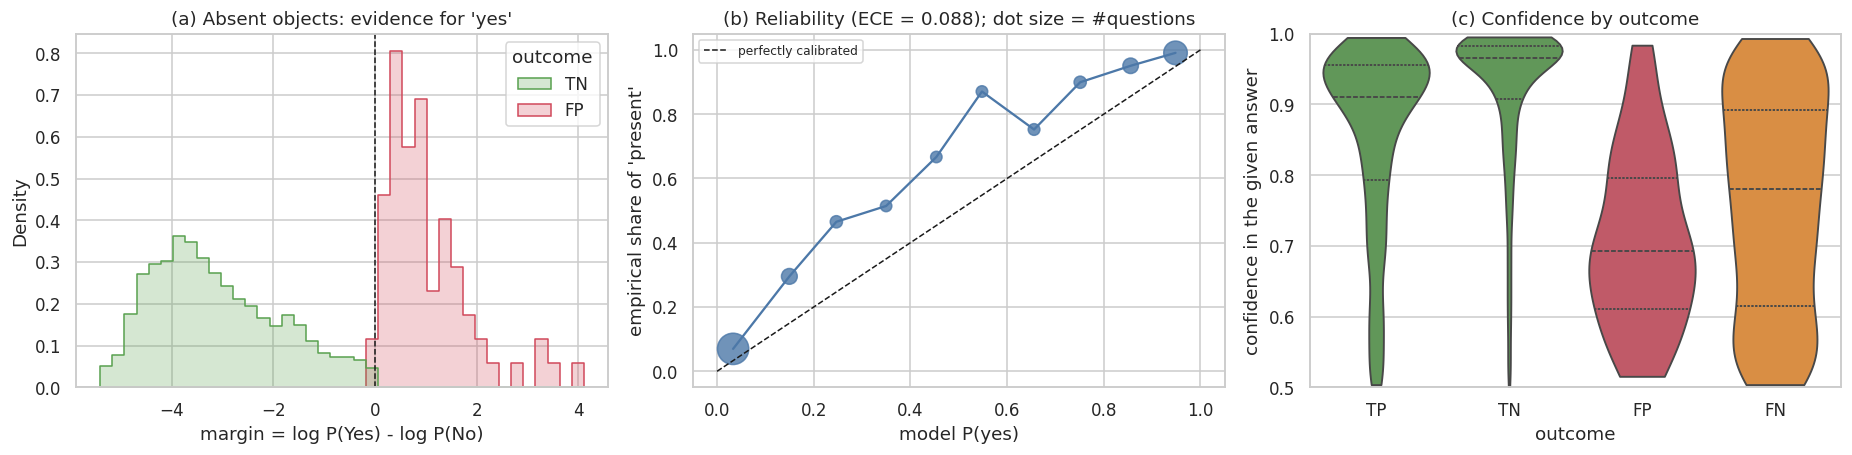

,AUROC,acc_at_0,best_threshold,acc_at_best
category,,,,
random,0.965,0.878,-1.078,0.908
popular,0.956,0.873,-1.000,0.900
adversarial,0.908,0.835,-0.500,0.841
ALL,0.944,0.862,-1.000,0.878


false positives: median confidence 0.693; 8% have confidence > 0.9 (true negatives: median 0.966)
AUROC (present vs absent, using the margin) = 0.944; accuracy at the model's own threshold = 0.862 vs. 0.878 at the best threshold (-1.00; fitted in-sample, for illustration)


In [9]:
from sklearn.metrics import roc_auc_score, roc_curve

fig, axes = plt.subplots(1, 3, figsize=(17, 4.3))
# (a) margins of absent objects, TN vs FP
neg = R[R.label_yes == 0]
sns.histplot(data=neg, x="margin", hue="outcome", hue_order=["TN", "FP"], palette={"TN": "#59a14f", "FP": "#d1495b"},
             bins=40, stat="density", common_norm=False, element="step", ax=axes[0])
axes[0].axvline(0, color="k", ls="--", lw=1); axes[0].set_xlabel("margin = log P(Yes) - log P(No)")
axes[0].set_title("(a) Absent objects: evidence for 'yes'")

# (b) reliability diagram on P(yes)
edges = np.linspace(0, 1, 11); b = np.digitize(R.p_yes, edges[1:-1])
rel = R.groupby(b).agg(conf=("p_yes", "mean"), acc=("label_yes", "mean"), n=("p_yes", "size"))
ece = (rel.n / rel.n.sum() * (rel.acc - rel.conf).abs()).sum()
axes[1].plot([0, 1], [0, 1], "k--", lw=1, label="perfectly calibrated")
axes[1].scatter(rel.conf, rel.acc, s=20 + 400 * rel.n / rel.n.max(), color="#4c78a8", alpha=.8)
axes[1].plot(rel.conf, rel.acc, color="#4c78a8")
axes[1].set_xlabel("model P(yes)"); axes[1].set_ylabel("empirical share of 'present'")
axes[1].set_title(f"(b) Reliability (ECE = {ece:.3f}); dot size = #questions"); axes[1].legend(fontsize=8)

# (c) confidence by outcome
order = ["TP", "TN", "FP", "FN"]
sns.violinplot(data=R, x="outcome", y="conf", order=order, cut=0, inner="quartile", ax=axes[2],
               palette={"TP": "#59a14f", "TN": "#59a14f", "FP": "#d1495b", "FN": "#f28e2b"})
axes[2].set_ylim(0.5, 1.0); axes[2].set_ylabel("confidence in the given answer"); axes[2].set_title("(c) Confidence by outcome")
plt.tight_layout(); plt.show()

# (d) ranking quality vs. threshold quality
rows = []
for c in CATS + ["ALL"]:
    d = R if c == "ALL" else R[R.category == c]
    auc = roc_auc_score(d.label_yes, d.margin)
    f_, t_, thr = roc_curve(d.label_yes, d.margin); j = int(np.argmax(t_ - f_))
    rows.append(dict(category=c, AUROC=auc, acc_at_0=d.correct.mean(), best_threshold=thr[j],
                     acc_at_best=((d.margin > thr[j]).astype(int) == d.label_yes).mean()))
auc_tab = pd.DataFrame(rows).set_index("category"); display(auc_tab.round(3))

fp_conf = R.loc[R.outcome == "FP", "conf"]; tn_conf = R.loc[R.outcome == "TN", "conf"]
print(f"false positives: median confidence {fp_conf.median():.3f}; {np.mean(fp_conf > .9)*100:.0f}% have confidence > 0.9 "
      f"(true negatives: median {tn_conf.median():.3f})")
print(f"AUROC (present vs absent, using the margin) = {auc_tab.loc['ALL','AUROC']:.3f}; accuracy at the model's own threshold = "
      f"{auc_tab.loc['ALL','acc_at_0']:.3f} vs. {auc_tab.loc['ALL','acc_at_best']:.3f} at the best threshold ({auc_tab.loc['ALL','best_threshold']:.2f}; fitted in-sample, for illustration)")
h2 = (fp_conf.median() > .8) and (auc_tab.loc["ALL", "acc_at_best"] > auc_tab.loc["ALL", "acc_at_0"])
VERDICTS.append(dict(hypothesis="H2 hallucinations are confident; margin still separates present/absent",
                     evidence=f"median FP confidence {fp_conf.median():.2f}; AUROC {auc_tab.loc['ALL','AUROC']:.2f}",
                     verdict="supported" if h2 else "not (fully) supported"))

### Interpretation
* **(a)** For absent objects the correct (green) mass sits at strongly negative margins; the red false-positive mass shows how far into "yes" territory the hallucinations go. If the red histogram has a large mode far to the right of 0 (not just a tail hugging 0), the model is not "unsure" - the evidence it uses for those questions genuinely says "yes".
* **(b)** A reliability diagram that bows away from the diagonal on the high-`P(yes)` side means that high-confidence "yes" answers are right less often than the model believes: the model is over-confident precisely when it claims to see something.
* **(c)** Compare the FP violin with the TP and TN violins: if they overlap, confidence cannot be used to filter hallucinations - a hallucinated "yes" looks, from the outside, like a genuine one.
* **(d)** The AUROC tells us whether the margin still orders present above absent objects. A high AUROC together with a clear gain in accuracy at a shifted threshold means the model does carry usable visual evidence, and a good part of the hallucination is a bias in the decision rule (a prior favouring "yes") rather than inability to see. Could be a behavioural clue (phase 2?)

## 6. Which objects are hallucinated? (H3)
Averages over 80 object classes can hide that the problem lives in a few of them. Here we compute the hallucination rate per object class, split it by negative-sampling regime in a heat-map, and test whether it tracks how common the object is in COCO-train (the proxy for LLaVA's training images).

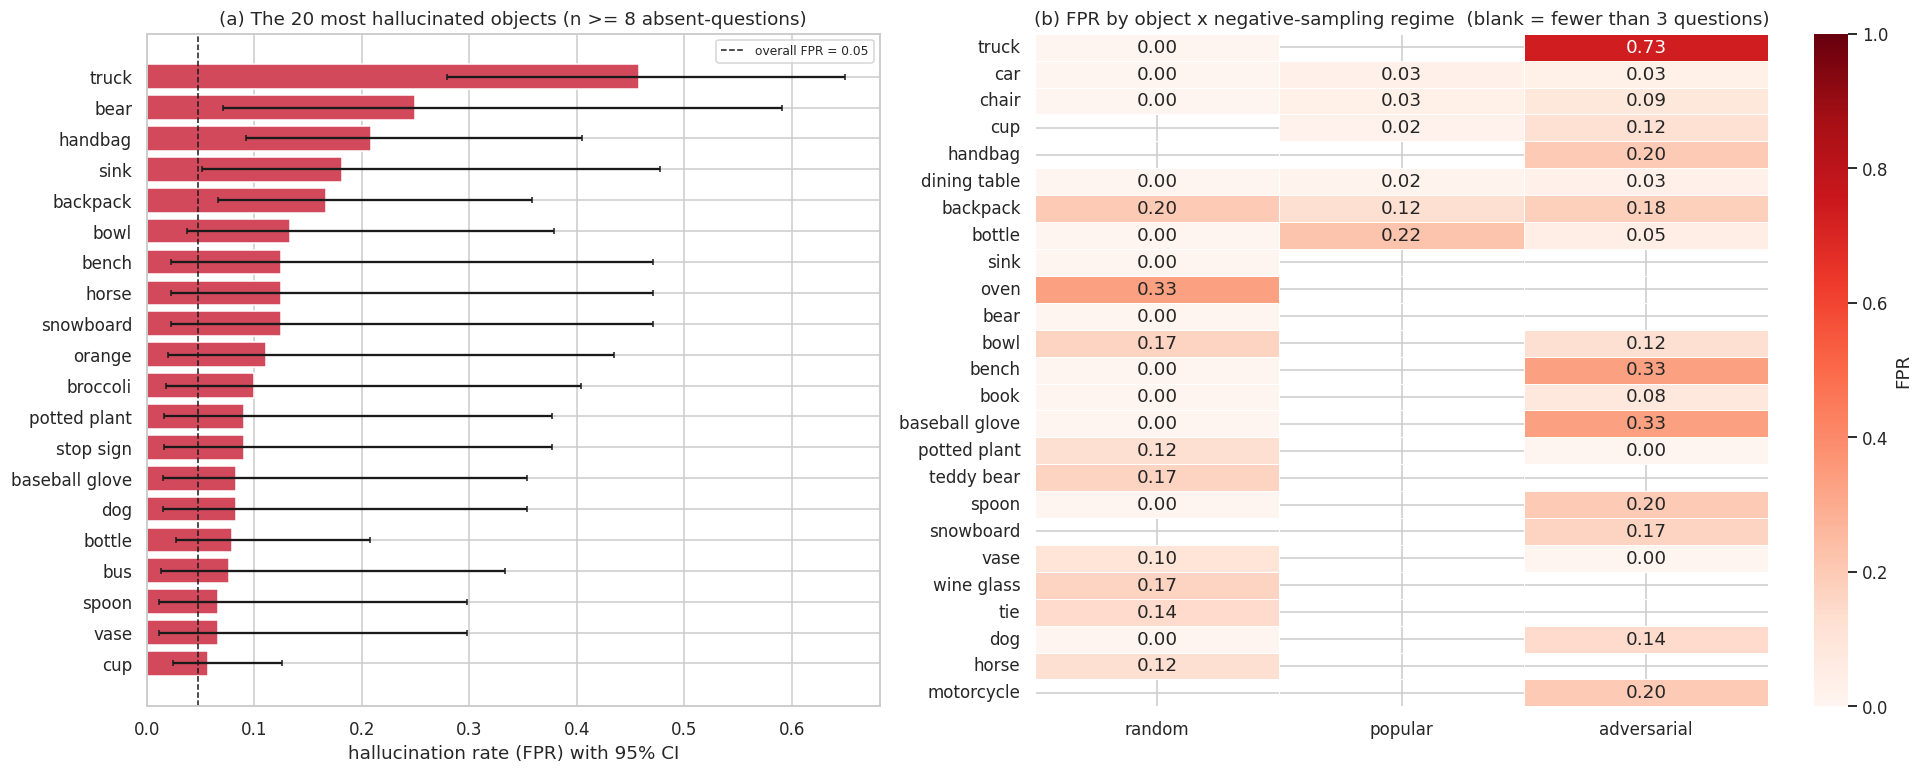

top-5 objects (truck, car, chair, cup, handbag) produce 49% of all hallucinations but only 35% of the absent-object questions
heterogeneity of FPR across objects: chi2 p = 3.7e-12


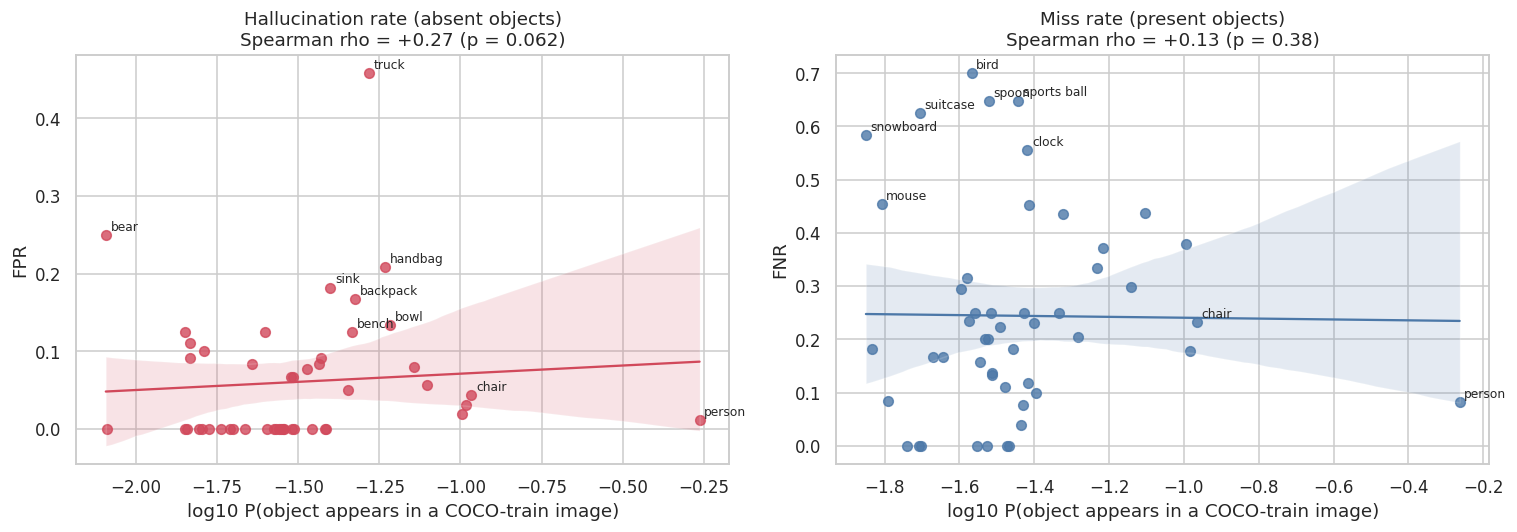

In [10]:
negs = R[(R.label_yes == 0) & R.obj.notna()].copy()
poss = R[(R.label_yes == 1) & R.obj.notna()].copy()

g = negs.groupby("obj").agg(n=("pred_yes", "size"), fp=("pred_yes", "sum")); g["fpr"] = g.fp / g.n
g[["lo", "hi"]] = [wilson(k, n) for k, n in zip(g.fp, g.n)]
gp = poss.groupby("obj").agg(n_pos=("pred_yes", "size"), tp=("pred_yes", "sum")); gp["fnr"] = 1 - gp.tp / gp.n_pos
G = g.join(gp).join(FREQ.rename("freq")); G["log_freq"] = np.log10(G.freq)
Gs = G[G.n >= MIN_N].sort_values("fpr", ascending=False)

fig = plt.figure(figsize=(18, 7.2))
gs = fig.add_gridspec(1, 2, width_ratios=[1, 1.25])
ax = fig.add_subplot(gs[0])
top = Gs.head(20)[::-1]
ax.barh(top.index, top.fpr, xerr=[top.fpr - top.lo, top.hi - top.fpr], color="#d1495b", capsize=2)
ax.axvline(negs.pred_yes.mean(), color="k", ls="--", lw=1, label=f"overall FPR = {negs.pred_yes.mean():.2f}")
ax.set_xlabel("hallucination rate (FPR) with 95% CI"); ax.set_title(f"(a) The 20 most hallucinated objects (n >= {MIN_N} absent-questions)"); ax.legend(fontsize=8)

# heat-map object x category
cell = negs.groupby(["obj", "category"]).pred_yes.agg(["mean", "size"])
rows_sel = negs.groupby("obj").pred_yes.sum().sort_values(ascending=False).head(25).index
H = cell["mean"].unstack().reindex(rows_sel)[CATS]; N = cell["size"].unstack().reindex(rows_sel)[CATS].fillna(0)
H = H.where(N >= MIN_CELL)
a2 = fig.add_subplot(gs[1])
sns.heatmap(H, annot=True, fmt=".2f", cmap="Reds", vmin=0, vmax=1, linewidths=.5, linecolor="white",
            cbar_kws={"label": "FPR"}, ax=a2, mask=H.isna())
a2.set_title(f"(b) FPR by object x negative-sampling regime  (blank = fewer than {MIN_CELL} questions)"); a2.set_ylabel(""); a2.set_xlabel("")
plt.tight_layout(); plt.show()

# concentration + heterogeneity
Gt = G[G.n >= MIN_N]
chi_p = stats.chi2_contingency(np.c_[Gt.fp, Gt.n - Gt.fp])[1]
top5 = G.sort_values("fp", ascending=False).head(5)
print(f"top-5 objects ({', '.join(top5.index)}) produce {top5.fp.sum() / G.fp.sum() * 100:.0f}% of all hallucinations "
      f"but only {top5.n.sum() / G.n.sum() * 100:.0f}% of the absent-object questions")
print(f"heterogeneity of FPR across objects: chi2 p = {chi_p:.2g}")
VERDICTS.append(dict(hypothesis="H3 hallucination is concentrated in few object classes",
                     evidence=f"top-5 objects = {top5.fp.sum() / G.fp.sum() * 100:.0f}% of FPs vs {top5.n.sum() / G.n.sum() * 100:.0f}% of questions; chi2 p={chi_p:.1g}",
                     verdict="supported" if (chi_p < .05 and top5.fp.sum() / G.fp.sum() > 1.5 * top5.n.sum() / G.n.sum()) else "not (fully) supported"))

# ---- frequency prior: FPR and FNR as a function of how common the object is in COCO-train ----
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, ycol, title, col in [(axes[0], "fpr", "Hallucination rate (absent objects)", "#d1495b"),
                             (axes[1], "fnr", "Miss rate (present objects)", "#4c78a8")]:
    need = (G.n >= MIN_N) if ycol == "fpr" else (G.n_pos >= MIN_N)
    d = G[need & G[ycol].notna()]
    sns.regplot(data=d, x="log_freq", y=ycol, ax=ax, color=col, scatter_kws=dict(s=40, alpha=.8), line_kws=dict(lw=1.5))
    rho, p = stats.spearmanr(d.log_freq, d[ycol])
    lab = d.sort_values(ycol, ascending=False).head(7).index.union(d.sort_values("log_freq").tail(2).index)
    for o in lab:
        ax.annotate(o, (d.loc[o, "log_freq"], d.loc[o, ycol]), fontsize=8, xytext=(3, 3), textcoords="offset points")
    ax.set_xlabel("log10 P(object appears in a COCO-train image)"); ax.set_ylabel(ycol.upper())
    ax.set_title(f"{title}\nSpearman rho = {rho:+.2f} (p = {p:.2g})")
    if ycol == "fpr": rho_fpr, p_fpr = rho, p
    else: rho_fnr, p_fnr = rho, p
plt.tight_layout(); plt.show()
VERDICTS.append(dict(hypothesis="H4 frequency prior: common objects over-claimed, rare ones missed",
                     evidence=f"rho(freq, FPR) = {rho_fpr:+.2f} (p={p_fpr:.2g}); rho(freq, FNR) = {rho_fnr:+.2f} (p={p_fnr:.2g})",
                     verdict="supported" if (rho_fpr > 0 and p_fpr < .05) else "not (fully) supported"))

### Interpretation
* **Concentration.** If a handful of classes carry most hallucinations, the problem is not "the model is bad at absent objects" in general but **specific to certain objects**. The heat-map then asks a sharper question: does the same object get hallucinated more under `adversarial` than under `random` sampling? A row that is pale on the left and dark on the right means the model hallucinates that object only when the scene makes it plausible - i.e. context-triggered hallucination - whereas a row that is dark everywhere means the object is hallucinated **irrespective of the scene** (an object-level prior). Check which rows fall into each group.
* **Frequency prior.** A positive slope in the left panel means: the more often an object shows up in COCO-train images (the data LLaVA's instruction tuning was built from), the more often the model claims it when it is absent. A negative slope in the right panel means rare objects are more likely to be overlooked when present. Together they would describe a model that has learned "say yes to common things, be sceptical of rare ones". Because frequency is also what the `popular` regime selects on, this slope is partly built into the benchmark - which is exactly why we need the next section, where we separate frequency from co-occurrence.
* Outliers (labelled points) are interesting in themselves: an object that is frequent but rarely hallucinated or rare but often hallucinated - breaks the simple frequency story and suggests another factor - such as visual similarity to other classes (e.g. fork/knife/spoon, car/truck/bus).

## 7. Frequency vs. co-occurrence: what exactly makes an absent object "plausible"? (H5)
`adversarial` negatives are chosen because the absent object **co-occurs with objects that are in the image**. Two things are entangled here: the object is common in general (frequency), and it is associated with the scene's content (co-occurrence beyond base rate). We separate them in three ways:

1. FPR as a function of the strongest co-occurrence between the absent object and any present object, `max_c P(obj | c)`.
2. A **hallucination map**: for the most-hallucinated objects (rows) and the most common context objects actually present (columns), the model's FPR in that cell - next to the corresponding training-data co-occurrence `P(obj | context)`. If the two maps look alike, the model hallucinates what the data says usually appears alongside the context.
3. A **logistic regression** of "hallucinated or not" (on absent objects) on frequency, co-occurrence lift (association beyond base rate) and scene clutter, so each factor is assessed holding the others fixed.

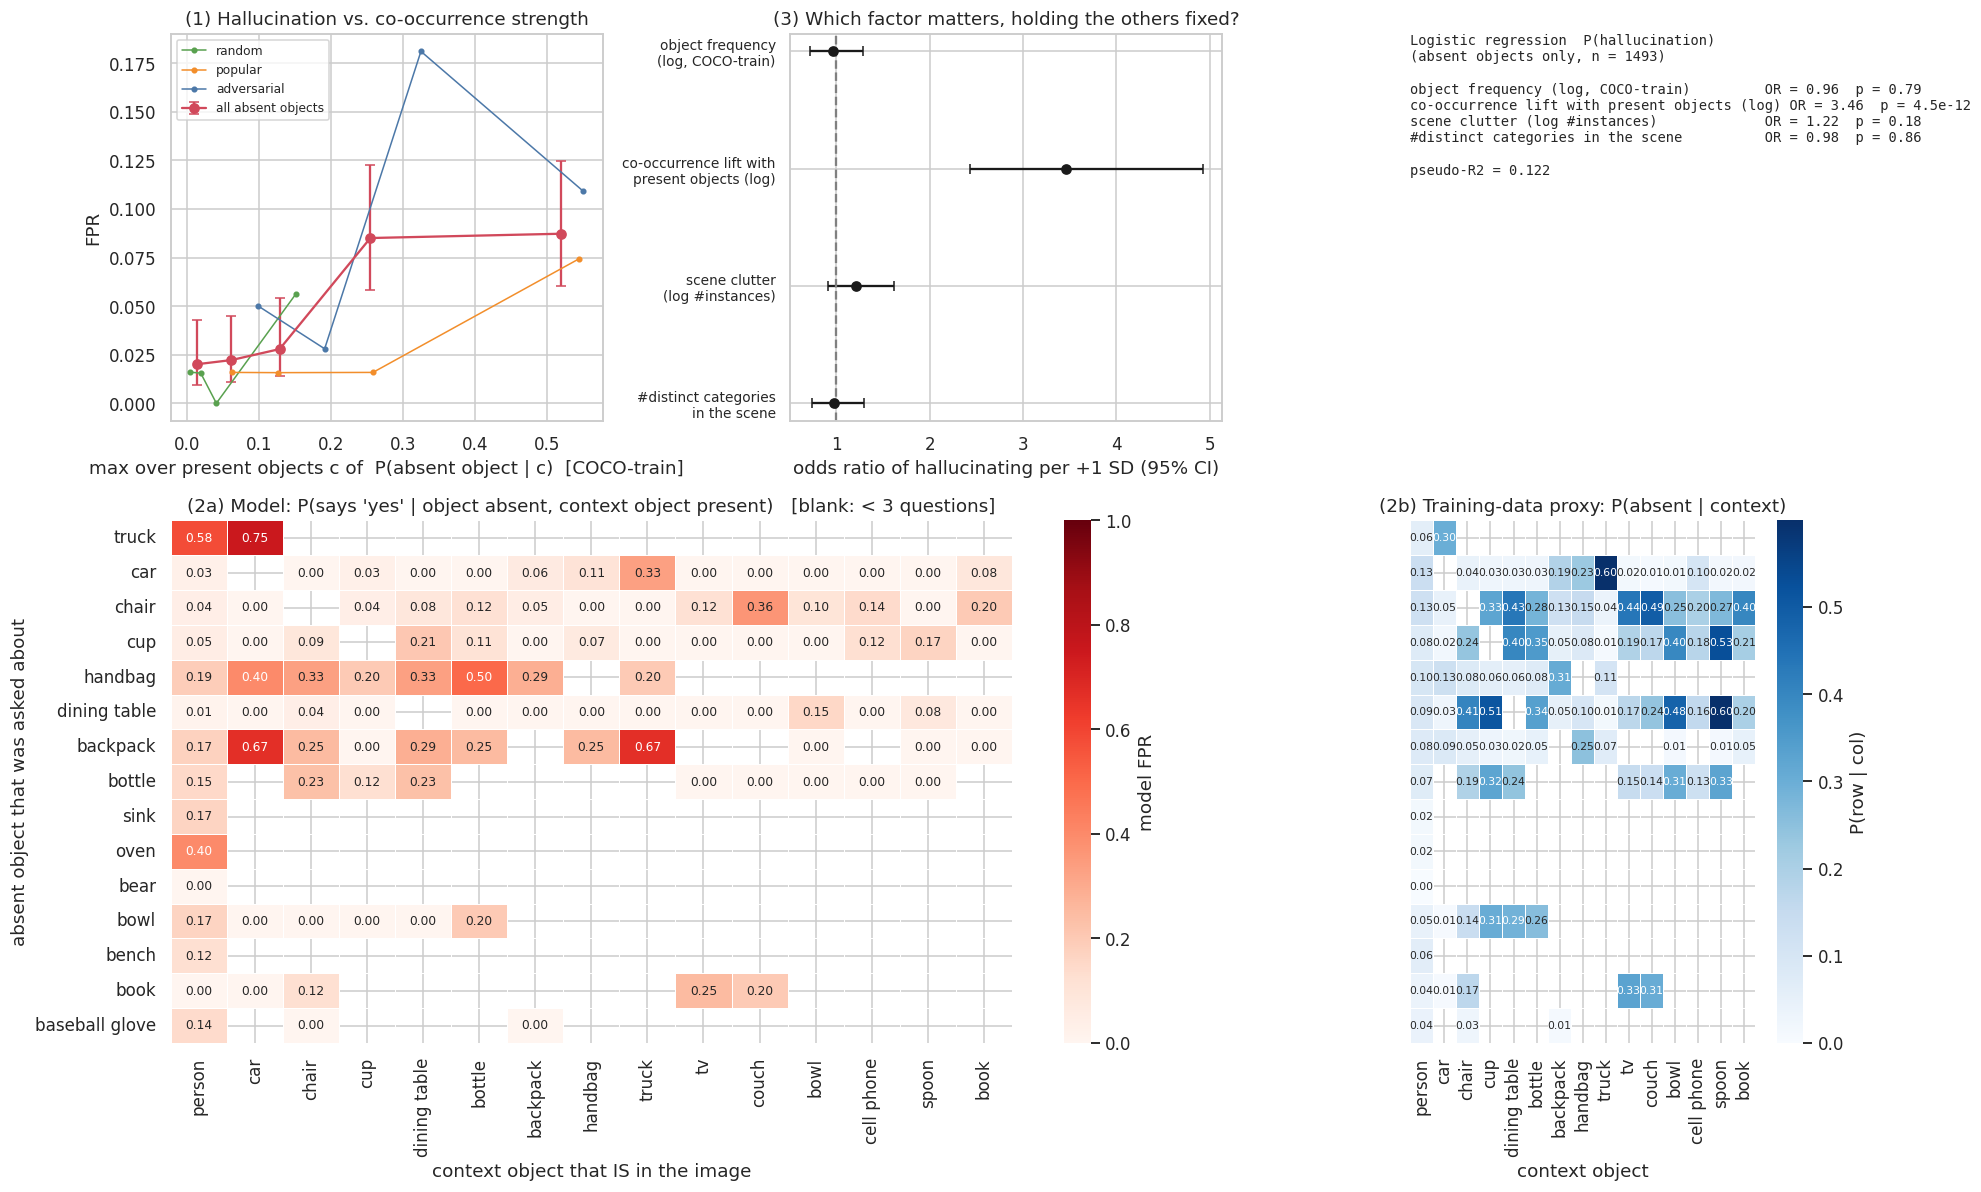

(1) Spearman(max co-occurrence, hallucinated) = +0.138 (p = 8.8e-08)
(2) model hallucination map vs. COCO co-occurrence map over 104 cells: Spearman = +0.27 (p = 0.006)
                  coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------
Intercept      -3.5584      0.187    -19.031      0.000      -3.925      -3.192
z_log_freq     -0.0398      0.149     -0.268      0.789      -0.331       0.251
z_log_lift      1.2422      0.180      6.920      0.000       0.890       1.594
z_log_inst      0.1951      0.147      1.328      0.184      -0.093       0.483
z_img_n_cat    -0.0246      0.144     -0.170      0.865      -0.307       0.258


In [11]:
import statsmodels.formula.api as smf

# ---- (1) FPR vs. strongest co-occurrence with a *present* object ----
d1 = negs.copy()
d1["cooc_bin"] = pd.qcut(d1.cooc_max, 5, duplicates="drop")
fig = plt.figure(figsize=(18, 11))
gs = fig.add_gridspec(2, 3, height_ratios=[1, 1.35])
ax = fig.add_subplot(gs[0, 0])
t = d1.groupby("cooc_bin").agg(n=("pred_yes", "size"), k=("pred_yes", "sum"), x=("cooc_max", "mean")); t["p"] = t.k / t.n
ci = np.array([wilson(k, n) for k, n in zip(t.k, t.n)])
ax.errorbar(t.x, t.p, yerr=[t.p - ci[:, 0], ci[:, 1] - t.p], marker="o", color="#d1495b", capsize=3, label="all absent objects")
for c, col in zip(CATS, ["#59a14f", "#f28e2b", "#4c78a8"]):
    dc = d1[d1.category == c]; tc = dc.groupby(pd.qcut(dc.cooc_max, 4, duplicates="drop")).agg(x=("cooc_max", "mean"), p=("pred_yes", "mean"))
    ax.plot(tc.x, tc.p, marker=".", lw=1, color=col, label=c)
ax.set_xlabel("max over present objects c of  P(absent object | c)  [COCO-train]"); ax.set_ylabel("FPR")
ax.set_title("(1) Hallucination vs. co-occurrence strength"); ax.legend(fontsize=8)
rho_c, p_c = stats.spearmanr(d1.cooc_max, d1.pred_yes)

# ---- (3) regression ----
d = negs.dropna(subset=["log_freq"]).copy()
d["log_lift"] = np.log(d.lift_max.clip(lower=1e-2)); d["log_inst"] = np.log1p(d.img_n_inst)
for c in ["log_freq", "log_lift", "log_inst", "img_n_cat"]:
    d["z_" + c] = (d[c] - d[c].mean()) / d[c].std()
d["fp"] = d.pred_yes
m = smf.logit("fp ~ z_log_freq + z_log_lift + z_log_inst + z_img_n_cat", data=d).fit(disp=0)
names = {"z_log_freq": "object frequency\n(log, COCO-train)", "z_log_lift": "co-occurrence lift with\npresent objects (log)",
         "z_log_inst": "scene clutter\n(log #instances)", "z_img_n_cat": "#distinct categories\nin the scene"}
co = m.params.drop("Intercept"); cin = m.conf_int().drop("Intercept")
ax = fig.add_subplot(gs[0, 1])
ax.errorbar(np.exp(co), range(len(co)), xerr=[np.exp(co) - np.exp(cin[0]), np.exp(cin[1]) - np.exp(co)], fmt="o", color="k", capsize=3)
ax.axvline(1, color="grey", ls="--"); ax.set_yticks(range(len(co))); ax.set_yticklabels([names[i] for i in co.index], fontsize=9)
ax.set_xlabel("odds ratio of hallucinating per +1 SD (95% CI)"); ax.set_title("(3) Which factor matters, holding the others fixed?")
ax.invert_yaxis()
a3 = fig.add_subplot(gs[0, 2]); a3.axis("off")
a3.text(0, 1, "Logistic regression  P(hallucination)\n(absent objects only, n = %d)\n\n" % len(d) +
        "\n".join(f"{names[i].replace(chr(10), ' '):42s} OR = {np.exp(m.params[i]):.2f}  p = {m.pvalues[i]:.2g}" for i in co.index) +
        f"\n\npseudo-R2 = {m.prsquared:.3f}", va="top", family="monospace", fontsize=9)

# ---- (2) hallucination map vs. training co-occurrence map ----
rows_sel = negs.groupby("obj").pred_yes.sum().sort_values(ascending=False).head(15).index.tolist()
ctx_counts = Counter(c for s in negs.ctx_list for c in s.split(",") if c)
cols_sel = [c for c, _ in ctx_counts.most_common(15)]
HM = pd.DataFrame(np.nan, index=rows_sel, columns=cols_sel); NM = HM.copy()
for o in rows_sel:
    sub = negs[negs.obj == o]
    for c in cols_sel:
        mask = sub.ctx_list.apply(lambda s: c in s.split(","))
        NM.at[o, c] = mask.sum()
        if mask.sum() >= MIN_CELL:
            HM.at[o, c] = sub.pred_yes[mask].mean()
PM = COND_MAT.loc[rows_sel, cols_sel]
ax1 = fig.add_subplot(gs[1, :2]); ax2 = fig.add_subplot(gs[1, 2])
sns.heatmap(HM, annot=True, fmt=".2f", cmap="Reds", vmin=0, vmax=1, mask=HM.isna(), linewidths=.5, linecolor="white",
            cbar_kws={"label": "model FPR"}, ax=ax1, annot_kws={"size": 8})
ax1.set_title(f"(2a) Model: P(says 'yes' | object absent, context object present)   [blank: < {MIN_CELL} questions]")
ax1.set_xlabel("context object that IS in the image"); ax1.set_ylabel("absent object that was asked about")
sns.heatmap(PM.where(HM.notna()), annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=PM.values.max(), mask=HM.isna(),
            linewidths=.5, linecolor="white", cbar_kws={"label": "P(row | col)"}, ax=ax2, annot_kws={"size": 7})
ax2.set_title("(2b) Training-data proxy: P(absent | context)"); ax2.set_yticklabels([]); ax2.set_xlabel("context object")
plt.tight_layout(); plt.show()

ok = HM.notna().values.ravel()
rho_map, p_map = stats.spearmanr(HM.values.ravel()[ok], PM.values.ravel()[ok]) if ok.sum() > 5 else (np.nan, np.nan)
print(f"(1) Spearman(max co-occurrence, hallucinated) = {rho_c:+.3f} (p = {p_c:.2g})")
print(f"(2) model hallucination map vs. COCO co-occurrence map over {ok.sum()} cells: Spearman = {rho_map:+.2f} (p = {p_map:.2g})")
print(m.summary().tables[1])
b_lift, p_lift = m.params["z_log_lift"], m.pvalues["z_log_lift"]
VERDICTS.append(dict(hypothesis="H5 co-occurrence prior beyond frequency",
                     evidence=f"OR(lift) = {np.exp(b_lift):.2f} (p={p_lift:.2g}); map-vs-COCO rho = {rho_map:+.2f}",
                     verdict="supported" if (b_lift > 0 and p_lift < .05) else "not (fully) supported"))

### Interpretation (Section 7)
* **(1)** If FPR climbs with the co-occurrence strength - also inside each regime (thin lines) - then "adversarial" is not just a label: the stronger the statistical link between the absent object and something that really is in the image, the more likely the model is to produce it.
* **(2a vs 2b)** Read the heat-maps cell by cell. A dark cell in (2a) whose counterpart in (2b) is also dark is a data-driven hallucination ("a dining table usually has a chair next to it, so I'll say yes to chair"). A dark cell in (2a) with a pale (2b) is a hallucination the co-occurrence statistics do **not** explain and that therefore needs a different explanation (e.g. visual similarity, or a language prior - see Section 9). The Spearman coefficient summarises how much of the pattern the data statistics explain.
* **(3)** The odds ratios tell which factor survives when the others are held fixed. If the co-occurrence lift stays positive and significant after controlling for frequency, co-occurrence adds explanatory power **beyond** "this object is common". If only frequency survives, the model is mainly applying a base-rate prior. Clutter terms test the alternative that the model simply gets "overwhelmed" in busy scenes.
* **Caveat.** COCO statistics are only a proxy for the training data of LLaVA (the instruction data are generated from COCO images with GPT-4, which adds its own biases), and this is correlational evidence. Phase II must test whether the model's internal representations actually encode these associations.